In [3]:
import pandas as pd

from campagne.caricamento import carica

dati = carica()

# i cinque numeri, su tre colonne che si comportano diversamente
for colonna in ["age", "campaign", "euribor3m"]:
    serie = dati[colonna]
    print(f"{colonna:12s} n={len(serie):6d} media={serie.mean():8.2f} mediana={serie.median():7.2f} "
          f"scarto={serie.std():6.2f} asimmetria={serie.skew():6.2f} min={serie.min():6.2f} max={serie.max():7.2f}")


age          n= 41188 media=   40.02 mediana=  38.00 scarto= 10.42 asimmetria=  0.78 min= 17.00 max=  98.00
campaign     n= 41188 media=    2.57 mediana=   2.00 scarto=  2.77 asimmetria=  4.76 min=  1.00 max=  56.00
euribor3m    n= 41188 media=    3.62 mediana=   4.86 scarto=  1.73 asimmetria= -0.71 min=  0.63 max=   5.04


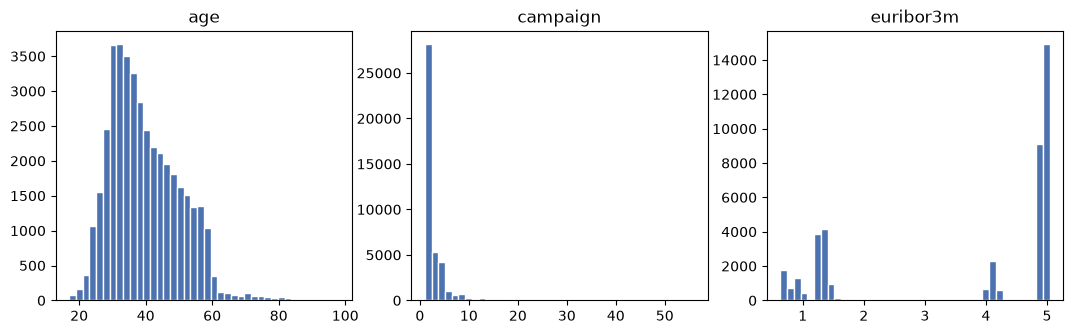

In [4]:
import matplotlib.pyplot as plt

figura, assi = plt.subplots(1, 3, figsize=(13, 3.5))
for ascissa, colonna in zip(assi, ["age", "campaign", "euribor3m"]):
    ascissa.hist(dati[colonna], bins=40, color="#4c72b0", edgecolor="white")
    ascissa.set_title(colonna)


In [5]:
import pandas as pd

from campagne.caricamento import carica, colonne_per_tipo

dati = carica()
numeriche, testuali = colonne_per_tipo(dati)

print(f"{len(dati)} righe, {len(dati.columns)} colonne")
print(f"quota di sì: {dati['y'].eq('yes').mean():.2%}")
print(f"nulli veri: {dati.isna().sum().sum()}, duplicati: {dati.duplicated().sum()}")

for colonna in testuali:
    if colonna == "y":
        continue
    quote = dati.groupby(colonna)["y"].apply(lambda c: c.eq("yes").mean())
    numerosita = dati.groupby(colonna)["y"].size()
    grandi = quote[numerosita >= 50]
    if len(grandi) > 1:
        print(f"{colonna:14s} da {grandi.min():.1%} a {grandi.max():.1%} "
              f"({grandi.idxmin()} → {grandi.idxmax()}), su {len(grandi)} gruppi sopra le 50 righe")


41188 righe, 21 colonne
quota di sì: 11.27%
nulli veri: 0, duplicati: 12
job            da 6.9% a 31.4% (blue-collar → student), su 12 gruppi sopra le 50 righe
marital        da 10.2% a 15.0% (married → unknown), su 4 gruppi sopra le 50 righe
education      da 7.8% a 14.5% (basic.9y → unknown), su 7 gruppi sopra le 50 righe
default        da 5.2% a 12.9% (unknown → no), su 2 gruppi sopra le 50 righe
housing        da 10.8% a 11.6% (unknown → yes), su 3 gruppi sopra le 50 righe
loan           da 10.8% a 11.3% (unknown → no), su 3 gruppi sopra le 50 righe
contact        da 5.2% a 14.7% (telephone → cellular), su 2 gruppi sopra le 50 righe
month          da 6.4% a 50.5% (may → mar), su 10 gruppi sopra le 50 righe
day_of_week    da 9.9% a 12.1% (mon → thu), su 5 gruppi sopra le 50 righe
poutcome       da 8.8% a 65.1% (nonexistent → success), su 3 gruppi sopra le 50 righe


In [2]:
import pandas as pd

from campagne.caricamento import carica, colonne_per_tipo


def controllo_qualita(dati: pd.DataFrame, etichetta: str = "y") -> pd.DataFrame:
    """Una riga per colonna, con tutto quello che serve a decidere se fidarsi."""
    numeriche, testuali = colonne_per_tipo(dati)
    righe = []
    for colonna in dati.columns:
        serie = dati[colonna]
        frequente = serie.value_counts().head(1)
        righe.append({
            "colonna": colonna,
            "tipo": "numerica" if colonna in numeriche else "testuale",
            "distinti": serie.nunique(),
            "nulli": int(serie.isna().sum()),
            "unknown": int((serie == "unknown").sum()) if colonna in testuali else 0,
            "valore_piu_frequente": frequente.index[0],
            "quota_del_piu_frequente": round(frequente.iloc[0] / len(dati), 4),
        })
    return pd.DataFrame(righe)


tabella = controllo_qualita(carica())
tabella.sort_values("quota_del_piu_frequente", ascending=False).head(10)


,colonna,tipo,distinti,nulli,unknown,valore_piu_frequente,quota_del_piu_frequente
12,pdays,numerica,27,0,0,999,0.9632
20,y,testuale,2,0,0,no,0.8873
13,previous,numerica,8,0,0,0,0.8634
14,poutcome,testuale,3,0,0,nonexistent,0.8634
6,loan,testuale,3,0,990,no,0.8243
4,default,testuale,3,0,8597,no,0.7912
7,contact,testuale,2,0,0,cellular,0.6347
2,marital,testuale,4,0,80,married,0.6052
5,housing,testuale,3,0,990,yes,0.5238
11,campaign,numerica,42,0,0,1,0.4283


In [3]:
def deriva(dati: pd.DataFrame, colonna: str, fette: int = 10) -> pd.DataFrame:
    """Come cambia una colonna lungo il file, con la quota di sì accanto."""
    taglio = pd.qcut(pd.Series(range(len(dati))), fette, labels=False)
    if pd.api.types.is_numeric_dtype(dati[colonna]):
        valore = dati.groupby(taglio)[colonna].mean().round(3)
    else:
        valore = dati.groupby(taglio)[colonna].apply(lambda c: c.value_counts(normalize=True).idxmax())
    quota = dati.groupby(taglio)["y"].apply(lambda c: c.eq("yes").mean()).round(3)
    return pd.DataFrame({colonna: valore, "quota_si": quota})


deriva(dati, "age")
deriva(dati, "contact")
deriva(dati, "campaign")


,campaign,quota_si
0,2.266,0.028
1,2.814,0.035
2,3.324,0.042
3,2.717,0.066
4,3.309,0.062
5,2.930,0.055
6,2.018,0.102
7,1.992,0.120
8,2.455,0.157
9,1.851,0.459
